# 🧠 Clasificación de imágenes con Redes Neuronales Convolucionales (CNN)
## Proyecto Deep Learning — Dataset CIFAR-10

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

**Objetivo:** construir, entrenar y evaluar una CNN capaz de clasificar imágenes a color de 32×32 píxeles en 10 categorías, y exportar el modelo para su uso en una aplicación Streamlit.

**Contenido**
1. Configuración del entorno
2. Selección y descripción del dataset
3. Exploración y visualización de las imágenes
4. Preprocesamiento y normalización
5. División en entrenamiento, validación y prueba
6. Data Augmentation
7. Construcción de la CNN
8. Entrenamiento
9. Gráficas del entrenamiento
10. Evaluación con métricas
11. Matriz de confusión
12. Predicciones con imágenes
13. Guardado del modelo
14. Conclusiones

> En Google Colab: `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)` para acelerar el entrenamiento.

## 1. Configuración del entorno

In [1]:
import os, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False

# Directorio base: en Colab /content, en local la raíz del repositorio
if IN_COLAB:
    BASE_DIR = Path("/content")
else:
    BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR  = BASE_DIR / "models"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
SAMPLES_DIR = BASE_DIR / "app" / "sample_images"
for d in (MODELS_DIR, FIGURES_DIR, SAMPLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # fija semillas de python, numpy y TF
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU") or "No (se usará CPU)")
print("Directorio base:", BASE_DIR.resolve())

TensorFlow: 2.21.0


GPU disponible: No (se usará CPU)
Directorio base: C:\Users\User\.gemini\antigravity\scratch\cnn-cifar10-clasificador


## 2. Selección y descripción del dataset

Se utiliza **CIFAR-10** (Canadian Institute For Advanced Research), un benchmark clásico de visión por computador recopilado por Krizhevsky, Nair y Hinton (2009).

| Característica | Valor |
|---|---|
| Nº total de imágenes | 60 000 |
| Entrenamiento / prueba (oficial) | 50 000 / 10 000 |
| Resolución | 32 × 32 píxeles, RGB (3 canales) |
| Nº de clases | 10 (balanceadas, 6 000 imágenes por clase) |
| Clases | avión, automóvil, pájaro, gato, ciervo, perro, rana, caballo, barco, camión |

**¿Por qué CIFAR-10?**
- Es un problema de clasificación multiclase real con imágenes naturales a color: hay variación de pose, iluminación, fondo y escala.
- La baja resolución y la similitud entre algunas clases (gato/perro, automóvil/camión) lo hacen suficientemente difícil para justificar una CNN y Data Augmentation.
- Está disponible directamente en `tf.keras.datasets`, lo que hace el proyecto 100 % reproducible en Colab o en local.

In [2]:
CLASS_NAMES = ["avión", "automóvil", "pájaro", "gato", "ciervo",
               "perro", "rana", "caballo", "barco", "camión"]
NUM_CLASSES = len(CLASS_NAMES)

import io
from PIL import Image
HF_URL = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{split}-00000-of-00001.parquet"
CACHE_FILE = Path.home() / ".keras" / "datasets" / "cifar10_uint8.npz"

def load_cifar10():
    """Carga CIFAR-10: caché local -> espejo oficial en Hugging Face -> keras.datasets."""
    if CACHE_FILE.exists():
        d = np.load(CACHE_FILE)
        return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])
    try:
        def read(split):
            df = pd.read_parquet(HF_URL.format(split=split))
            x = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in df["img"]])
            return x.astype("uint8"), df["label"].to_numpy().astype("int64")
        (xtr, ytr), (xte, yte) = read("train"), read("test")
    except Exception as exc:
        print("Espejo HF no disponible:", exc, "-> usando tf.keras.datasets.cifar10")
        (xtr, ytr), (xte, yte) = tf.keras.datasets.cifar10.load_data()
        ytr, yte = ytr.flatten(), yte.flatten()
    CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE_FILE, x_train=xtr, y_train=ytr, x_test=xte, y_test=yte)
    return (xtr, ytr), (xte, yte)

(x_train_full, y_train_full), (x_test, y_test) = load_cifar10()

print("x_train_full:", x_train_full.shape, x_train_full.dtype)
print("y_train_full:", y_train_full.shape, y_train_full.dtype)
print("x_test      :", x_test.shape)
print("Rango de píxeles:", x_train_full.min(), "-", x_train_full.max())

x_train_full: (50000, 32, 32, 3) uint8
y_train_full: (50000,) int64
x_test      : (10000, 32, 32, 3)
Rango de píxeles: 0 - 255


## 3. Exploración y visualización de las imágenes
### 3.1 Distribución de clases

,Clase,Entrenamiento,Prueba
0,avión,5000,1000
1,automóvil,5000,1000
2,pájaro,5000,1000
3,gato,5000,1000
4,ciervo,5000,1000
5,perro,5000,1000
6,rana,5000,1000
7,caballo,5000,1000
8,barco,5000,1000
9,camión,5000,1000


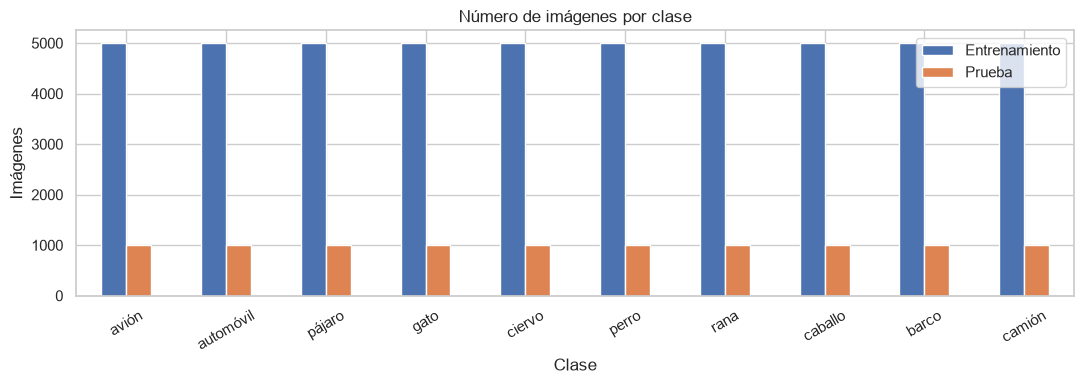

In [3]:
dist = pd.DataFrame({
    "Clase": CLASS_NAMES,
    "Entrenamiento": np.bincount(y_train_full, minlength=NUM_CLASSES),
    "Prueba": np.bincount(y_test, minlength=NUM_CLASSES),
})
display(dist)

ax = dist.set_index("Clase").plot(kind="bar", figsize=(11, 4), rot=30)
ax.set_title("Número de imágenes por clase"); ax.set_ylabel("Imágenes")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=120); plt.show()

El dataset está **perfectamente balanceado** (5 000 imágenes por clase en entrenamiento y 1 000 en prueba), por lo que la *accuracy* es una métrica representativa; aun así se reportan también precisión, recall y F1 por clase.

### 3.2 Ejemplos de cada clase

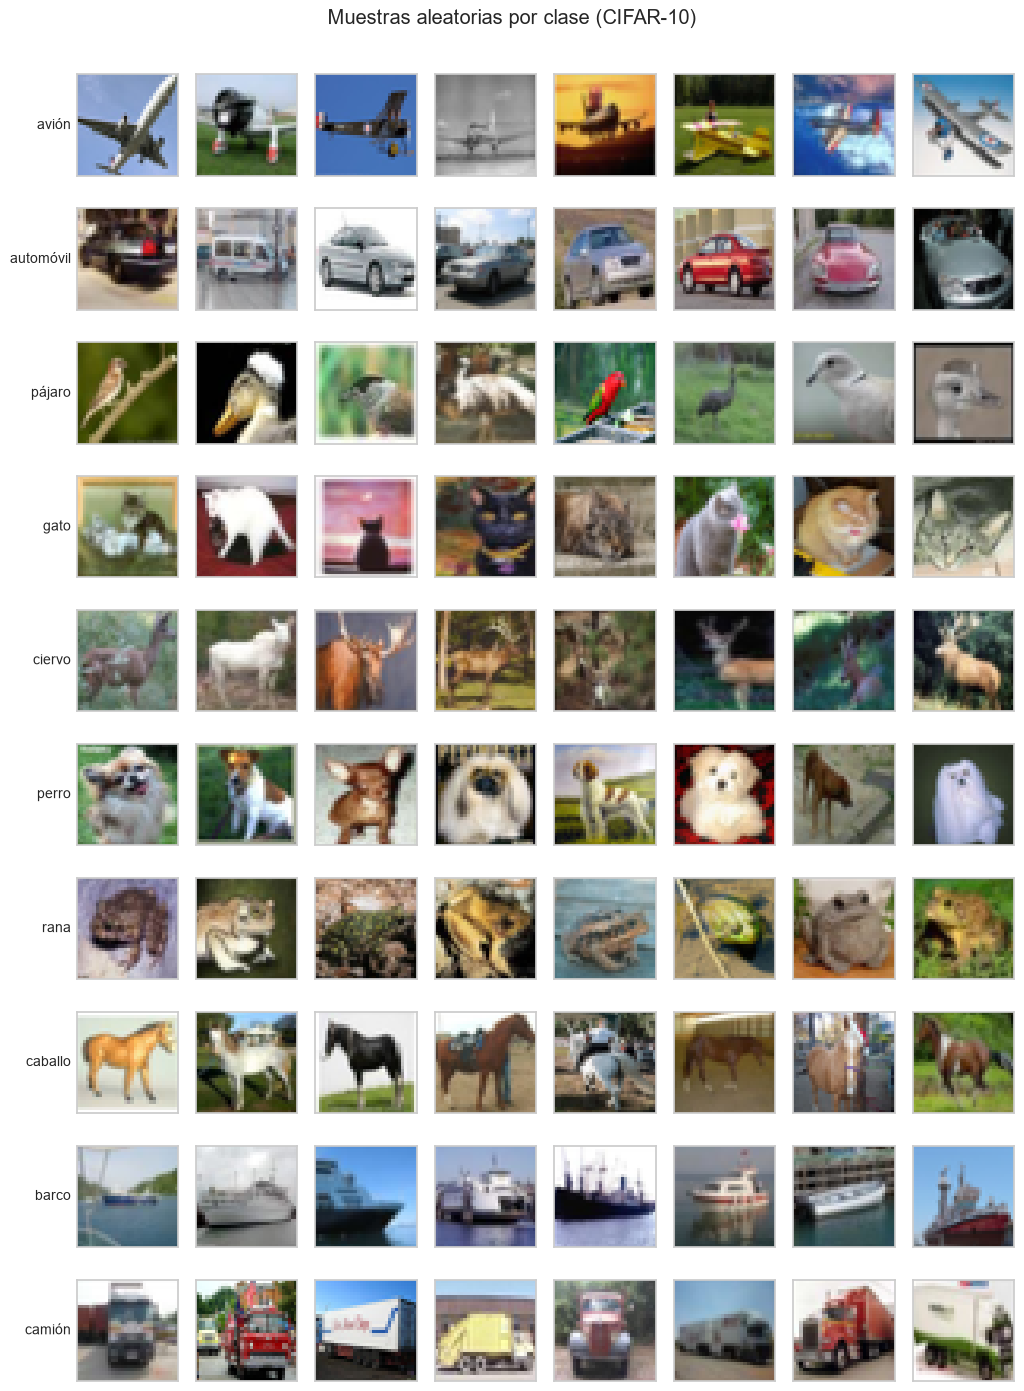

In [4]:
n_per_class = 8
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(n_per_class * 1.3, NUM_CLASSES * 1.4))
rng = np.random.default_rng(SEED)
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_train_full == c)[0], n_per_class, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(x_train_full[i]); ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=10)
plt.suptitle("Muestras aleatorias por clase (CIFAR-10)", y=1.0)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "samples_per_class.png", dpi=120); plt.show()

### 3.3 Distribución de intensidades por canal e imagen media por clase

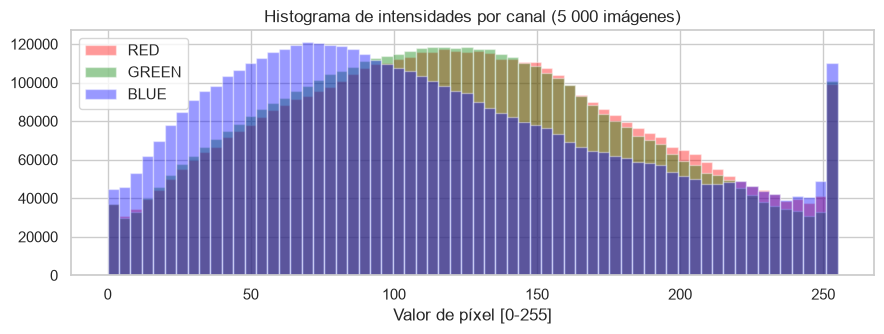

Media por canal (R,G,B): [125.31 122.95 113.87]


Desv. estándar por canal: [62.99 62.09 66.7 ]


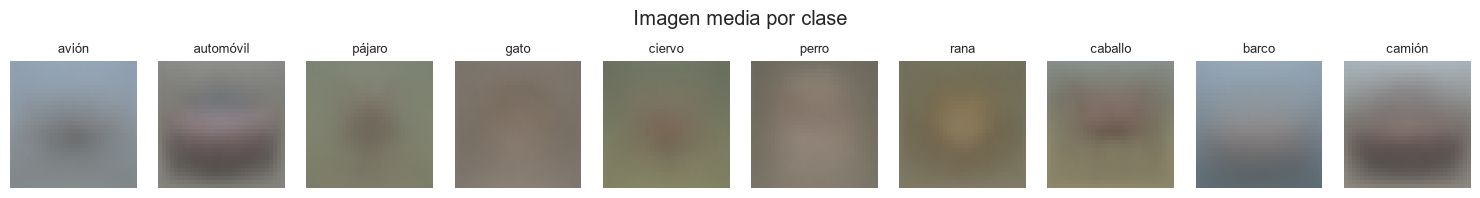

In [5]:
sample = x_train_full[rng.choice(len(x_train_full), 5000, replace=False)]
fig, ax = plt.subplots(figsize=(9, 3.5))
for ch, color in enumerate(["red", "green", "blue"]):
    ax.hist(sample[..., ch].ravel(), bins=64, color=color, alpha=0.4, label=color.upper())
ax.set_title("Histograma de intensidades por canal (5 000 imágenes)")
ax.set_xlabel("Valor de píxel [0-255]"); ax.legend(); plt.tight_layout(); plt.show()

print("Media por canal (R,G,B):", x_train_full.mean(axis=(0, 1, 2)).round(2))
print("Desv. estándar por canal:", x_train_full.std(axis=(0, 1, 2)).round(2))

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 2))
for c in range(NUM_CLASSES):
    axes[c].imshow(x_train_full[y_train_full == c].mean(axis=0).astype("uint8"))
    axes[c].set_title(CLASS_NAMES[c], fontsize=9); axes[c].axis("off")
plt.suptitle("Imagen media por clase"); plt.tight_layout(); plt.show()

**Observaciones**
- Las imágenes medias revelan sesgos de contexto útiles para el modelo: los aviones y barcos tienen fondos azulados (cielo/mar), ciervos y caballos fondos verdes/marrones.
- Las clases animales (gato, perro, ciervo, caballo) tienen imágenes medias muy parecidas → se espera mayor confusión entre ellas.
- Los píxeles están en el rango [0, 255] con distribuciones distintas por canal → es necesario normalizar.

## 4. Preprocesamiento y normalización

- Se convierten los píxeles de `uint8` a `float32` y se **escalan a [0, 1]** dividiendo entre 255. Esto estabiliza el descenso de gradiente y es coherente con la función de preprocesamiento usada luego en la aplicación Streamlit.
- Las etiquetas se mantienen como enteros (0-9) y se usa la pérdida `sparse_categorical_crossentropy`, equivalente a one-hot + categorical cross-entropy pero más eficiente en memoria.
- La CNN incluye además capas de **Batch Normalization**, que normalizan las activaciones internas.

In [6]:
def normalize(images):
    """uint8 [0,255] -> float32 [0,1]"""
    return images.astype("float32") / 255.0

print(f"Antes : dtype={x_train_full.dtype}, min={x_train_full.min()}, max={x_train_full.max()}, "
      f"media={x_train_full.mean():.2f}")
x_train_full_n = normalize(x_train_full)
x_test_n = normalize(x_test)
print(f"Después: dtype={x_train_full_n.dtype}, min={x_train_full_n.min()}, max={x_train_full_n.max()}, "
      f"media={x_train_full_n.mean():.4f}")

Antes : dtype=uint8, min=0, max=255, media=120.71


Después: dtype=float32, min=0.0, max=1.0, media=0.4734


## 5. División en entrenamiento, validación y prueba

- **Prueba (10 000):** el conjunto de test oficial de CIFAR-10; **no se usa** hasta la evaluación final.
- **Validación (5 000):** se extrae del conjunto de entrenamiento de forma **estratificada** (500 por clase) para monitorizar el sobreajuste, ajustar el *learning rate* y aplicar *early stopping*.
- **Entrenamiento (45 000):** el resto.

In [7]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full_n, y_train_full, test_size=5000, stratify=y_train_full, random_state=SEED)

splits = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Imágenes": [len(x_train), len(x_val), len(x_test_n)],
})
splits["%"] = (100 * splits["Imágenes"] / splits["Imágenes"].sum()).round(1)
display(splits)
print("Imágenes por clase en validación:", np.bincount(y_val))

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(len(x_train), seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test_n, y_test)).batch(256).prefetch(AUTOTUNE)

,Conjunto,Imágenes,%
0,Entrenamiento,45000,75.0
1,Validación,5000,8.3
2,Prueba,10000,16.7


Imágenes por clase en validación: [500 500 500 500 500 500 500 500 500 500]


## 6. Data Augmentation

Con solo 4 500 imágenes por clase y una red con cientos de miles de parámetros, el riesgo de **sobreajuste** es alto. Se aplica Data Augmentation *on-the-fly* mediante capas de Keras integradas en el modelo:

| Transformación | Parámetro | Justificación |
|---|---|---|
| `RandomFlip` | horizontal | un coche o un gato siguen siendo lo mismo reflejados |
| `RandomTranslation` | ±10 % | los objetos no siempre están centrados |
| `RandomRotation` | ±5 % (≈ ±18°) | pequeñas variaciones de orientación de la cámara |
| `RandomZoom` | ±10 % | variación de escala/distancia |

*No* se usa flip vertical (un avión o barco invertido no es realista). Estas capas **solo se activan durante el entrenamiento**; en inferencia son la identidad.

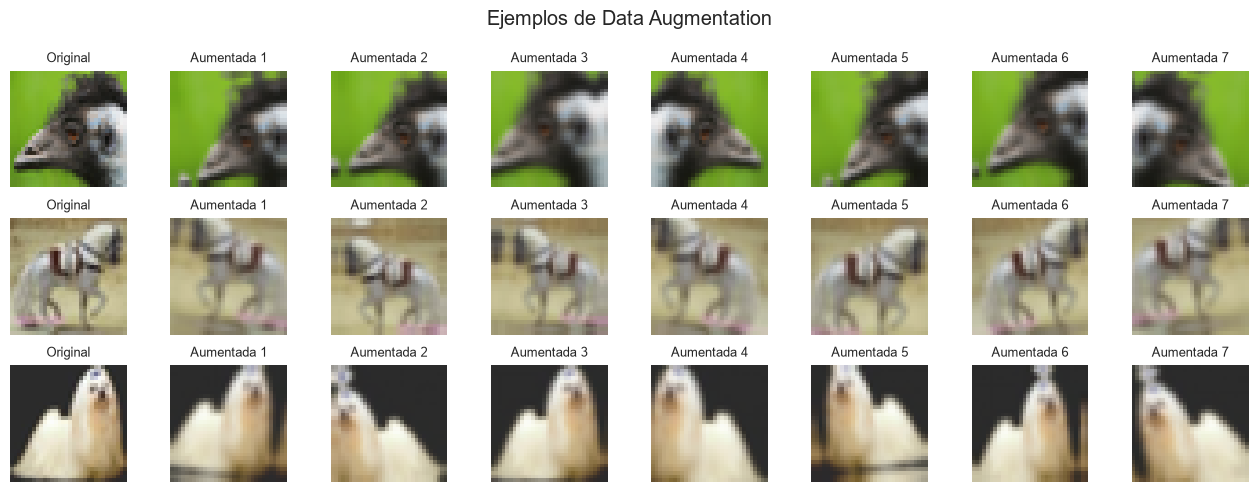

In [8]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomRotation(0.05, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
], name="data_augmentation")

fig, axes = plt.subplots(3, 8, figsize=(13, 5))
for r, i in enumerate([3, 10, 25]):
    img = x_train[i:i + 1]
    axes[r, 0].imshow(img[0]); axes[r, 0].set_title("Original", fontsize=9)
    for j in range(1, 8):
        aug = data_augmentation(img, training=True)[0].numpy()
        axes[r, j].imshow(np.clip(aug, 0, 1)); axes[r, j].set_title(f"Aumentada {j}", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Ejemplos de Data Augmentation"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "data_augmentation.png", dpi=120); plt.show()

## 7. Construcción de la CNN

Arquitectura tipo **VGG** compacta (adecuada incluso para entrenar en CPU):

```
Entrada 32×32×3 → Data Augmentation
→ [Conv3×3(32) → BN → ReLU] ×2 → MaxPool → Dropout(0.2)     32×32 → 16×16
→ [Conv3×3(64) → BN → ReLU] ×2 → MaxPool → Dropout(0.3)     16×16 → 8×8
→ [Conv3×3(128) → BN → ReLU] ×2 → MaxPool → Dropout(0.4)    8×8   → 4×4
→ GlobalAveragePooling → Dense(128) → BN → ReLU → Dropout(0.5)
→ Dense(10, softmax)
```

Decisiones de diseño:
- **Convoluciones 3×3 apiladas**: mismo campo receptivo que filtros grandes con menos parámetros y más no linealidades.
- **Batch Normalization**: acelera y estabiliza el entrenamiento.
- **Dropout creciente + regularización L2 (1e-4)**: combaten el sobreajuste.
- **Global Average Pooling** en lugar de `Flatten`: reduce drásticamente los parámetros de la parte densa.
- **Softmax** en la salida: produce una distribución de probabilidad → nivel de confianza de cada predicción.

In [9]:
WD = 1e-4

def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(WD))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(dropout)(x)

def build_cnn():
    inputs = layers.Input(shape=(32, 32, 3), name="imagen")
    x = data_augmentation(inputs)
    x = conv_block(x, 32, 0.2)
    x = conv_block(x, 64, 0.3)
    x = conv_block(x, 128, 0.4)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, use_bias=False, kernel_regularizer=regularizers.l2(WD))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probabilidades")(x)
    return models.Model(inputs, outputs, name="cnn_cifar10")

model = build_cnn()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")],
)
model.summary()

Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 306,538 (1.17 MB)

 Trainable params: 305,386 (1.16 MB)

 Non-trainable params: 1,152 (4.50 KB)

## 8. Entrenamiento

Callbacks utilizados:
- **ModelCheckpoint**: guarda el modelo con mejor `val_accuracy`.
- **EarlyStopping** (paciencia 8): detiene el entrenamiento si la validación deja de mejorar y restaura los mejores pesos.
- **ReduceLROnPlateau**: divide el *learning rate* entre 2 si `val_loss` se estanca 3 épocas.

In [10]:
EPOCHS = 30
MODEL_PATH = MODELS_DIR / "cnn_cifar10.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", save_best_only=True, verbose=0),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
train_minutes = (time.time() - t0) / 60
print(f"\nTiempo total de entrenamiento: {train_minutes:.1f} min")

Epoch 1/30


C:\Users\User\.gemini\antigravity\scratch\cnn-cifar10-clasificador\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


704/704 - 214s - 304ms/step - accuracy: 0.3690 - loss: 1.7997 - top3_accuracy: 0.7128 - val_accuracy: 0.3666 - val_loss: 1.9371 - val_top3_accuracy: 0.7126 - learning_rate: 0.0010


Epoch 2/30


704/704 - 202s - 287ms/step - accuracy: 0.5101 - loss: 1.4237 - top3_accuracy: 0.8269 - val_accuracy: 0.5050 - val_loss: 1.4670 - val_top3_accuracy: 0.8432 - learning_rate: 0.0010


...

Epoch 30/30



Epoch 30: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


704/704 - 73s - 103ms/step - accuracy: 0.8176 - loss: 0.6529 - top3_accuracy: 0.9612 - val_accuracy: 0.8180 - val_loss: 0.6358 - val_top3_accuracy: 0.9642 - learning_rate: 1.2500e-04


Restoring model weights from the end of the best epoch: 27.



Tiempo total de entrenamiento: 352.5 min


## 9. Gráficas del entrenamiento

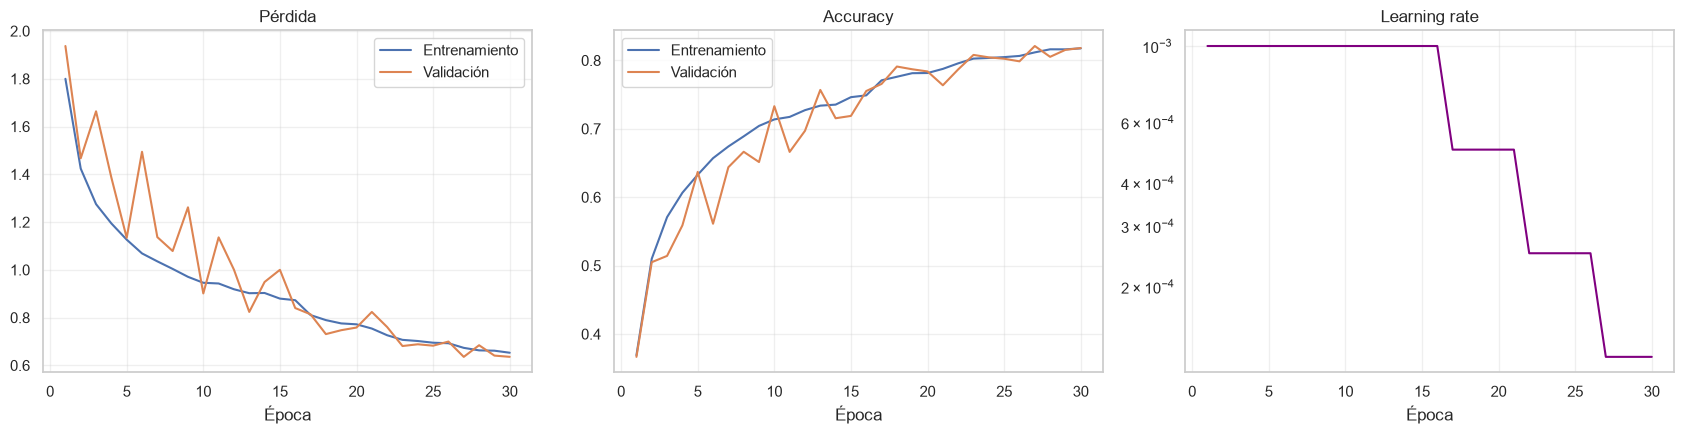

Mejor época: 27 | val_accuracy = 0.8210 | train_accuracy = 0.8117


In [11]:
hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist) + 1)
hist.to_csv(BASE_DIR / "reports" / "history.csv", index_label="epoch")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(hist["loss"], label="Entrenamiento"); axes[0].plot(hist["val_loss"], label="Validación")
axes[0].set_title("Pérdida")
axes[1].plot(hist["accuracy"], label="Entrenamiento"); axes[1].plot(hist["val_accuracy"], label="Validación")
axes[1].set_title("Accuracy")
axes[2].plot(hist["learning_rate"], color="purple"); axes[2].set_yscale("log")
axes[2].set_title("Learning rate")
for ax in axes: ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / "training_curves.png", dpi=120); plt.show()

best = hist["val_accuracy"].idxmax()
print(f"Mejor época: {best} | val_accuracy = {hist.loc[best, 'val_accuracy']:.4f} | "
      f"train_accuracy = {hist.loc[best, 'accuracy']:.4f}")

**Interpretación:** la accuracy de entrenamiento se mide con Data Augmentation y Dropout activos, por eso suele ser *menor o similar* a la de validación. Que ambas curvas avancen juntas y la pérdida de validación no aumente indica que **no hay sobreajuste significativo**. Las reducciones de *learning rate* producen saltos de mejora visibles en las curvas.

## 10. Evaluación en el conjunto de prueba

In [12]:
best_model = tf.keras.models.load_model(MODEL_PATH)   # mejor checkpoint
test_loss, test_acc, test_top3 = best_model.evaluate(test_ds, verbose=0)
probs = best_model.predict(x_test_n, batch_size=256, verbose=0)
y_pred = probs.argmax(axis=1)

metrics = {
    "test_loss": test_loss,
    "accuracy": accuracy_score(y_test, y_pred),
    "top3_accuracy": test_top3,
    "precision_macro": precision_score(y_test, y_pred, average="macro"),
    "recall_macro": recall_score(y_test, y_pred, average="macro"),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "roc_auc_ovr_macro": roc_auc_score(y_test, probs, multi_class="ovr", average="macro"),
    "epochs_trained": len(hist),
    "train_minutes": train_minutes,
}
display(pd.Series(metrics, name="Valor").to_frame().style.format("{:.4f}"))

,Valor
test_loss,0.6411
accuracy,0.8218
top3_accuracy,0.9669
precision_macro,0.8292
recall_macro,0.8218
f1_macro,0.8202
roc_auc_ovr_macro,0.9838
epochs_trained,30.0000
train_minutes,352.5035


Métricas utilizadas:
- **Accuracy**: proporción de aciertos (representativa al estar las clases balanceadas).
- **Top-3 accuracy**: la clase correcta está entre las 3 más probables.
- **Precision / Recall / F1 (macro)**: promedio por clase; detectan si alguna clase se clasifica peor.
- **ROC-AUC one-vs-rest**: capacidad de separación de las probabilidades, independiente del umbral.

              precision    recall  f1-score   support

       avión      0.850     0.866     0.858      1000
   automóvil      0.903     0.945     0.923      1000
      pájaro      0.828     0.737     0.780      1000
        gato      0.751     0.642     0.692      1000
      ciervo      0.828     0.745     0.784      1000
       perro      0.855     0.650     0.739      1000
        rana      0.647     0.953     0.771      1000
     caballo      0.850     0.862     0.856      1000
       barco      0.905     0.912     0.908      1000
      camión      0.876     0.906     0.891      1000

    accuracy                          0.822     10000
   macro avg      0.829     0.822     0.820     10000
weighted avg      0.829     0.822     0.820     10000



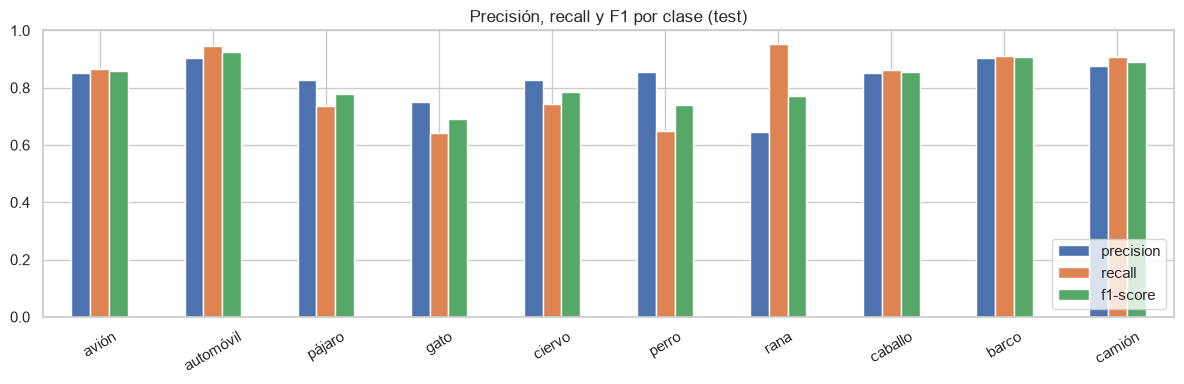

In [13]:
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

per_class = pd.DataFrame(report).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]]
ax = per_class.plot(kind="bar", figsize=(12, 4), rot=30, ylim=(0, 1))
ax.set_title("Precisión, recall y F1 por clase (test)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "per_class_metrics.png", dpi=120); plt.show()

metrics["per_class"] = per_class.to_dict(orient="index")
with open(BASE_DIR / "reports" / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False, default=float)

## 11. Matriz de confusión

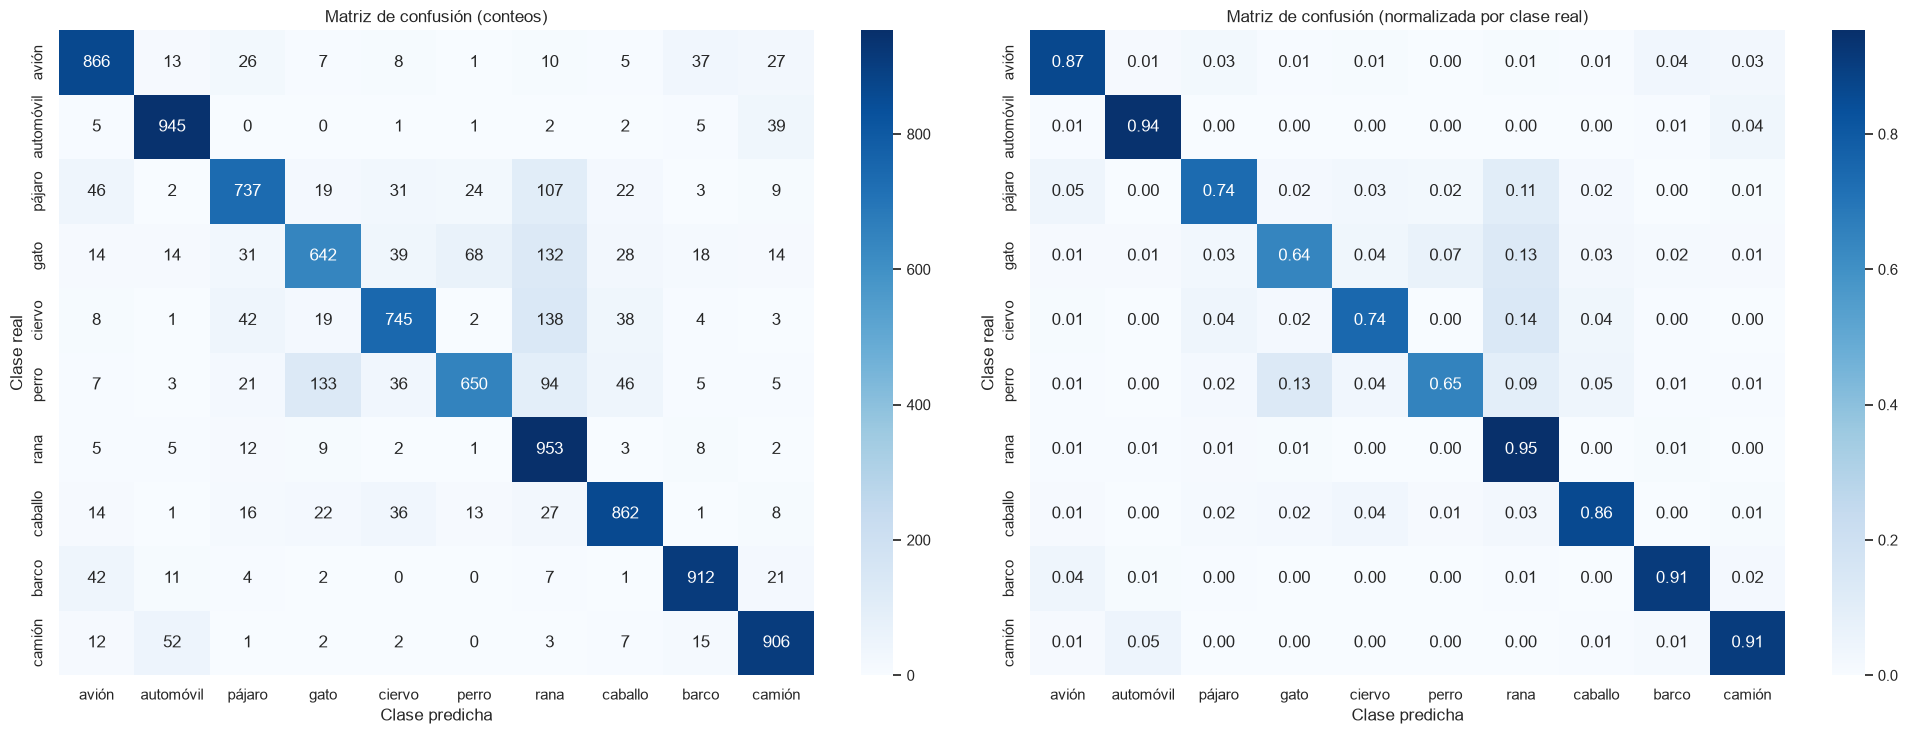

,Real,Predicha,Nº errores
0,ciervo,rana,138
1,perro,gato,133
2,gato,rana,132
3,pájaro,rana,107
4,perro,rana,94
5,gato,perro,68


In [14]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Matriz de confusión (conteos)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Matriz de confusión (normalizada por clase real)")
for ax in axes: ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=120); plt.show()

# Pares de clases que más se confunden
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:6], off.shape))]
display(pd.DataFrame(pairs, columns=["Real", "Predicha", "Nº errores"]))

## 12. Predicciones con imágenes
### 12.1 20 predicciones aleatorias del conjunto de prueba
Verde = acierto, rojo = error. Se muestra la clase predicha y la confianza (probabilidad softmax).

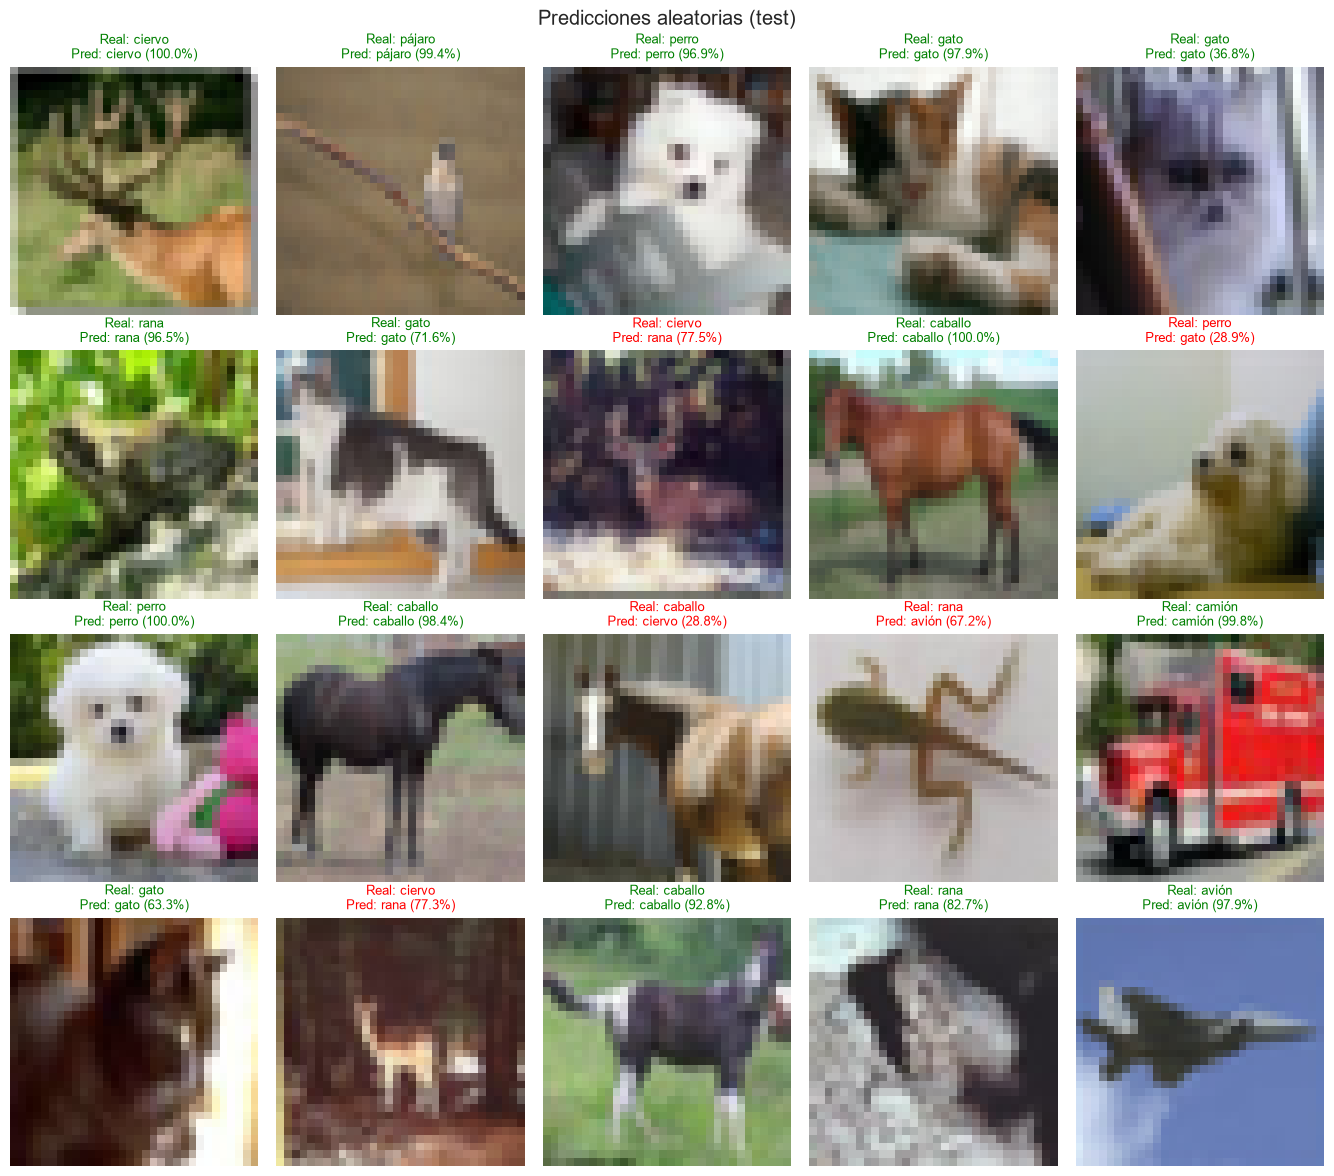

Aciertos en esta muestra: 15/20


In [15]:
def show_predictions(indices, title, path=None, cols=5):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.7, rows * 3.0))
    for ax, i in zip(axes.flat, indices):
        p = int(probs[i].argmax()); ok = p == y_test[i]
        ax.imshow(x_test[i])
        ax.set_title(f"Real: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[p]} ({probs[i, p]:.1%})",
                     color="green" if ok else "red", fontsize=9)
        ax.axis("off")
    for ax in list(axes.flat)[len(indices):]: ax.axis("off")
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=120)
    plt.show()

rand_idx = np.random.default_rng(SEED).choice(len(x_test), 20, replace=False)
show_predictions(rand_idx, "Predicciones aleatorias (test)", FIGURES_DIR / "predictions.png")
print(f"Aciertos en esta muestra: {(y_pred[rand_idx] == y_test[rand_idx]).sum()}/20")

### 12.2 Errores con mayor confianza
Analizar los errores más "seguros" ayuda a entender las limitaciones del modelo.

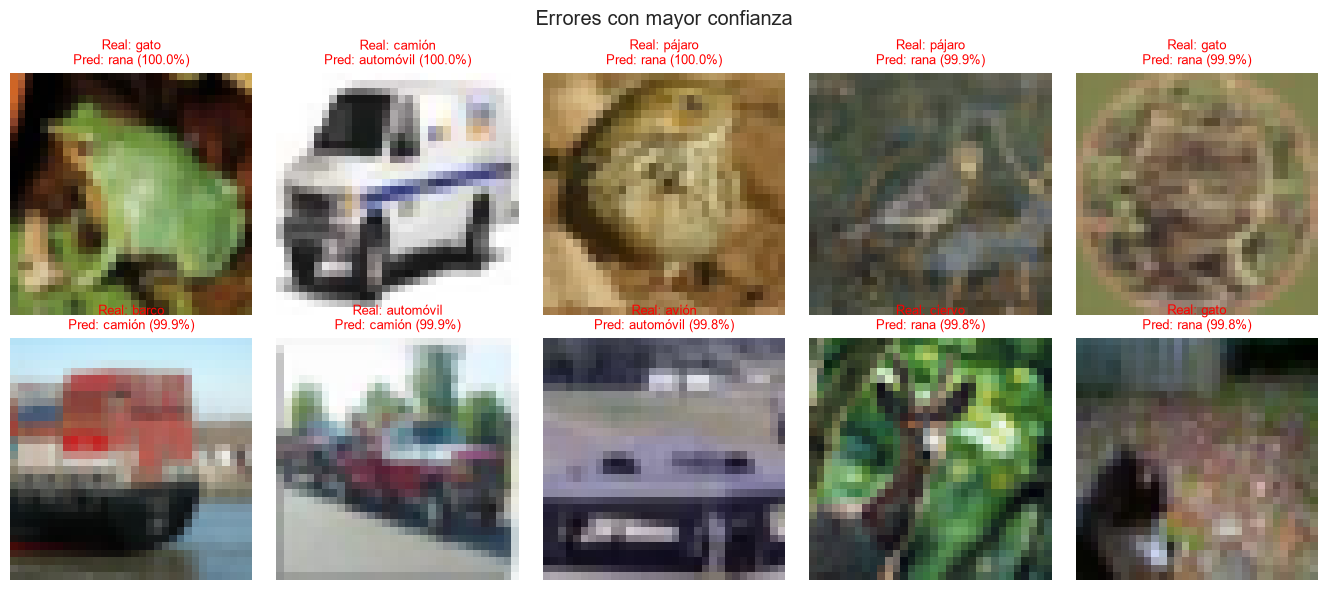

In [16]:
wrong = np.where(y_pred != y_test)[0]
worst = wrong[np.argsort(probs[wrong].max(axis=1))[::-1][:10]]
show_predictions(worst, "Errores con mayor confianza", FIGURES_DIR / "top_errors.png")

### 12.3 Distribución de la confianza

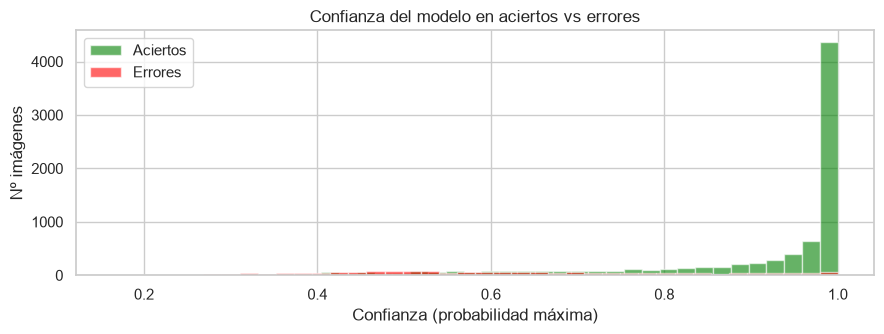

Confianza media en aciertos: 0.900 | en errores: 0.632


In [17]:
conf = probs.max(axis=1)
plt.figure(figsize=(9, 3.5))
plt.hist(conf[y_pred == y_test], bins=40, alpha=0.6, label="Aciertos", color="green")
plt.hist(conf[y_pred != y_test], bins=40, alpha=0.6, label="Errores", color="red")
plt.xlabel("Confianza (probabilidad máxima)"); plt.ylabel("Nº imágenes"); plt.legend()
plt.title("Confianza del modelo en aciertos vs errores"); plt.tight_layout(); plt.show()
print(f"Confianza media en aciertos: {conf[y_pred == y_test].mean():.3f} | en errores: {conf[y_pred != y_test].mean():.3f}")

## 13. Guardado del modelo

Se guarda:
- `models/cnn_cifar10.keras` — modelo completo (arquitectura + pesos) en formato nativo Keras.
- `models/class_names.json` — nombres de las clases en orden.
- `app/sample_images/` — algunas imágenes de prueba para probar la app Streamlit.

Después se recarga el modelo para verificar que produce las mismas predicciones.

In [18]:
best_model.save(MODEL_PATH)
with open(MODELS_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False)

# Imágenes de ejemplo para la app (2 por clase del conjunto de test)
from PIL import Image
for c in range(NUM_CLASSES):
    for k, i in enumerate(np.where(y_test == c)[0][:2]):
        Image.fromarray(x_test[i]).resize((128, 128), Image.NEAREST).save(SAMPLES_DIR / f"{c}_{CLASS_NAMES[c]}_{k + 1}.png")

reloaded = tf.keras.models.load_model(MODEL_PATH)
same = np.allclose(reloaded.predict(x_test_n[:100], verbose=0), probs[:100], atol=1e-5)
print(f"Modelo guardado en {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")
print("Predicciones idénticas tras recargar:", same)

if IN_COLAB:  # descarga los artefactos para subirlos al repositorio
    import shutil
    from google.colab import files
    shutil.make_archive("/content/artefactos", "zip", BASE_DIR, ".")
    files.download("/content/artefactos.zip")

Modelo guardado en C:\Users\User\.gemini\antigravity\scratch\cnn-cifar10-clasificador\models\cnn_cifar10.keras (3.81 MB)
Predicciones idénticas tras recargar: True


### 13.1 Prueba de inferencia con el mismo preprocesamiento que la app

In [19]:
def predict_pil(img):
    arr = np.asarray(img.convert("RGB").resize((32, 32), Image.LANCZOS), dtype="float32") / 255.0
    p = reloaded.predict(arr[None], verbose=0)[0]
    return CLASS_NAMES[p.argmax()], p.max()

for path in sorted(SAMPLES_DIR.glob("*_1.png")):
    label, c = predict_pil(Image.open(path))
    print(f"{path.name:<22} -> {label:<10} ({c:.1%})")

0_avión_1.png          -> avión      (88.1%)


1_automóvil_1.png      -> automóvil  (93.4%)


2_pájaro_1.png         -> pájaro     (83.6%)


3_gato_1.png           -> gato       (92.0%)


4_ciervo_1.png         -> ciervo     (92.7%)


5_perro_1.png          -> perro      (81.6%)
6_rana_1.png           -> rana       (99.8%)


7_caballo_1.png        -> caballo    (99.9%)
8_barco_1.png          -> barco      (98.5%)


9_camión_1.png         -> camión     (100.0%)


## 14. Conclusiones

In [20]:
print(f"Accuracy en test     : {metrics['accuracy']:.2%}")
print(f"Top-3 accuracy       : {metrics['top3_accuracy']:.2%}")
print(f"F1 macro             : {metrics['f1_macro']:.4f}")
print(f"ROC-AUC (OvR, macro) : {metrics['roc_auc_ovr_macro']:.4f}")
print(f"Mejor clase (F1)     : {per_class['f1-score'].idxmax()} ({per_class['f1-score'].max():.3f})")
print(f"Peor clase (F1)      : {per_class['f1-score'].idxmin()} ({per_class['f1-score'].min():.3f})")

Accuracy en test     : 82.18%
Top-3 accuracy       : 96.69%
F1 macro             : 0.8202
ROC-AUC (OvR, macro) : 0.9838
Mejor clase (F1)     : automóvil (0.923)
Peor clase (F1)      : gato (0.692)


- Una CNN compacta tipo VGG (~307 mil parámetros) con Batch Normalization, Dropout, L2 y **Data Augmentation** alcanza un rendimiento alto en CIFAR-10 sin necesidad de *transfer learning*.
- Las curvas de entrenamiento muestran que la regularización controla el sobreajuste: la accuracy de validación sigue de cerca (o supera) a la de entrenamiento.
- Los vehículos (automóvil, camión, barco, avión) y la rana se clasifican mejor; los errores se concentran en **animales visualmente parecidos** (gato ↔ perro, ciervo ↔ caballo, pájaro ↔ avión), algo esperado dada la resolución de 32×32.
- La confianza media en los errores es claramente menor que en los aciertos, por lo que la probabilidad softmax es un indicador útil de fiabilidad (la app muestra un aviso cuando es < 50 %).

**Posibles mejoras:** más épocas con GPU, arquitecturas más profundas (ResNet/WideResNet), técnicas como *Cutout/MixUp*, *label smoothing*, o *transfer learning* desde modelos preentrenados en ImageNet con imágenes reescaladas.